*Exploracion descriptiva de los datos Oscar*

In [2]:
# Importacion de Librerias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display # Esta es una libreria dedicada a jupiter la cual nos permite ver nuestras tablas con mejor formato
import re # Regex: para validación y extracción de patrones de texto

In [3]:
# Importacion de tablas

df_match = pd.read_csv('../data/processed/Match_LaLiga.csv')
df_team_attr = pd.read_csv('../data/processed/Team_Attributes_LaLiga.csv')
df_player_attr = pd.read_csv('../data/processed/Player_Attributes_LaLiga.csv')
df_player = pd.read_csv('../data/processed/Player_LaLiga.csv')
df_team = pd.read_csv('../data/processed/Team_LaLiga.csv')

In [4]:
# Con esto quito el límite de columnas de Pandas para poder hacer scroll completo
pd.set_option('display.max_columns', None)
print("1. TABLA: PARTIDOS (Match)")
display(df_match.head(200))
df_match.info()



1. TABLA: PARTIDOS (Match)


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,home_player_X1,home_player_X2,home_player_X3,home_player_X4,home_player_X5,home_player_X6,home_player_X7,home_player_X8,home_player_X9,home_player_X10,home_player_X11,away_player_X1,away_player_X2,away_player_X3,away_player_X4,away_player_X5,away_player_X6,away_player_X7,away_player_X8,away_player_X9,away_player_X10,away_player_X11,home_player_Y1,home_player_Y2,home_player_Y3,home_player_Y4,home_player_Y5,home_player_Y6,home_player_Y7,home_player_Y8,home_player_Y9,home_player_Y10,home_player_Y11,away_player_Y1,away_player_Y2,away_player_Y3,away_player_Y4,away_player_Y5,away_player_Y6,away_player_Y7,away_player_Y8,away_player_Y9,away_player_Y10,away_player_Y11,home_player_1,home_player_2,home_player_3,home_player_4,home_player_5,home_player_6,home_player_7,home_player_8,home_player_9,home_player_10,home_player_11,away_player_1,away_player_2,away_player_3,away_player_4,away_player_5,away_player_6,away_player_7,away_player_8,away_player_9,away_player_10,away_player_11,goal,shoton,shotoff,foulcommit,card,cross,corner,possession,B365H,B365D,B365A,BWH,BWD,BWA,IWH,IWD,IWA,LBH,LBD,LBA,PSH,PSD,PSA,WHH,WHD,WHA,SJH,SJD,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
0,21518,21518,21518,2008/2009,1,2008-08-30 00:00:00,530023,10267,8661,3,0,1.0,2.0,4.0,6.0,8.0,4.0,6.0,3.0,5.0,7.0,5.0,1.0,2.0,4.0,6.0,8.0,5.0,4.0,6.0,5.0,4.0,6.0,1.0,3.0,3.0,3.0,3.0,6.0,6.0,8.0,8.0,8.0,11.0,1.0,3.0,3.0,3.0,3.0,5.0,7.0,7.0,9.0,11.0,11.0,19435.0,34007.0,34029.0,37479.0,34008.0,32761.0,30666.0,2802.0,37459.0,41468.0,30909.0,33845.0,24131.0,33856.0,33849.0,33861.0,38160.0,37491.0,38398.0,37411.0,21414.0,25574.0,<goal><value><comment>n</comment><stats><goals...,<shoton><value><stats><shoton>1</shoton></stat...,<shotoff><value><stats><shotoff>1</shotoff></s...,<foulcommit><value><stats><foulscommitted>1</f...,<card><value><comment>y</comment><stats><ycard...,<cross><value><stats><corners>1</corners></sta...,<corner><value><stats><corners>1</corners></st...,<possession><value><comment>53</comment><event...,1.70,3.6,5.25,1.65,3.35,5.00,1.70,3.30,4.50,1.62,3.50,4.50,NaN,NaN,NaN,1.67,3.30,4.50,1.73,3.50,5.00,1.65,3.40,4.50,1.75,3.30,5.00,1.67,3.40,5.00
1,21519,21518,21518,2008/2009,1,2008-08-31 00:00:00,530084,8371,10205,1,1,1.0,2.0,4.0,6.0,8.0,4.0,6.0,3.0,5.0,7.0,5.0,1.0,2.0,4.0,6.0,8.0,2.0,4.0,6.0,8.0,4.0,6.0,1.0,3.0,3.0,3.0,3.0,6.0,6.0,8.0,8.0,8.0,11.0,1.0,3.0,3.0,3.0,3.0,7.0,7.0,7.0,7.0,10.0,10.0,24591.0,72541.0,33865.0,11778.0,38521.0,42369.0,33870.0,38424.0,30907.0,33641.0,108809.0,41466.0,30279.0,56678.0,38458.0,40599.0,37436.0,38746.0,30958.0,38362.0,38551.0,31020.0,<goal><value><comment>n</comment><stats><goals...,<shoton />,<shotoff />,<foulcommit />,<card><value><comment>y</comment><stats><ycard...,<cross />,<corner />,<possession />,2.80,3.3,2.50,2.90,3.25,2.20,2.80,3.10,2.30,2.75,3.00,2.38,NaN,NaN,NaN,2.62,3.20,2.30,2.75,3.20,2.60,2.90,3.20,2.25,2.75,3.20,2.50,2.80,3.25,2.30
2,21520,21518,21518,2008/2009,1,2008-08-31 00:00:00,530085,9783,8633,2,1,1.0,2.0,4.0,8.0,6.0,2.0,4.0,6.0,8.0,4.0,6.0,1.0,2.0,4.0,6.0,8.0,4.0,6.0,3.0,5.0,7.0,5.0,1.0,3.0,3.0,3.0,3.0,7.0,7.0,7.0,7.0,10.0,10.0,1.0,3.0,3.0,3.0,3.0,6.0,6.0,8.0,8.0,8.0,11.0,33018.0,111190.0,37451.0,41167.0,34104.0,37447.0,30271.0,33758.0,31045.0,37441.0,34956.0,30657.0,30962.0,25921.0,30670.0,28467.0,37259.0,32765.0,25759.0,30655.0,30834.0,34602.0,<goal><value><comment>n</comment><stats><goals...,<shoton><value><stats><blocked>1</blocked></st...,<shotoff><value><stats><shotoff>1</shotoff></s...,<foulcommit><value><stats><foulscommitted>1</f...,<card><value><comment>y</comment><stats><ycard...,<cross><value><stats><crosses>1</crosses></sta...,<corner><value><stats><corners>1</corners></st...,<possession><value><comment>44</comment><event...,3.50,3.3,2.10,3.90,3.25,1.85,3.20,3.10,2.10,3.20,3.20,2.00,NaN,NaN,NaN,3.30,3.25,1.95,4.00,3.50,1.90,3.25,3.25,2.00,3.50,3.20,2.10,3.25,3.25,2.10
3,21521,21518,2

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3040 entries, 0 to 3039
Columns: 115 entries, id to BSA
dtypes: float64(96), int64(9), object(10)
memory usage: 2.7+ MB


In [5]:
pd.set_option('display.max_rows', None)
df_match.dtypes


id                    int64
country_id            int64
league_id             int64
season               object
stage                 int64
date                 object
match_api_id          int64
home_team_api_id      int64
away_team_api_id      int64
home_team_goal        int64
away_team_goal        int64
home_player_X1      float64
home_player_X2      float64
home_player_X3      float64
home_player_X4      float64
home_player_X5      float64
home_player_X6      float64
home_player_X7      float64
home_player_X8      float64
home_player_X9      float64
home_player_X10     float64
home_player_X11     float64
away_player_X1      float64
away_player_X2      float64
away_player_X3      float64
away_player_X4      float64
away_player_X5      float64
away_player_X6      float64
away_player_X7      float64
away_player_X8      float64
away_player_X9      float64
away_player_X10     float64
away_player_X11     float64
home_player_Y1      float64
home_player_Y2      float64
home_player_Y3      

*Limpieza de variables XML y objetos*
Procese las columnas que venían anidadas en formato XML (como tiros, tarjetas y faltas) usando expresiones regulares para extraer y contar los eventos. El texto plano lo converti en variables numéricas puras. Este paso es clave porque los algoritmos de Machine Learning solo entienden números, de esta forma obtenemos mas variables y tenemos un formato mas limpio.
A si mismo converti la fecha de objeto a fecha para poder hacer analiis en series de tiempo

In [6]:
# Tomamos las columnas que son objeto XML
columnas_conteo = ['goal', 'shoton', 'shotoff', 'foulcommit', 'card', 'cross', 'corner']

def contar_eventos_xml(texto):
    """Cuenta eventos por etiqueta. Retorna NaN si no hay registro (para no dañar promedios)."""
    if pd.isna(texto) or str(texto).strip() == '':
        return np.nan 
    return len(re.findall(r'<value>', str(texto)))

def extraer_porcentaje_posesion(texto):
    """Extrae el porcentaje final exacto de la posesión local."""
    if pd.isna(texto) or str(texto).strip() == '':
        return np.nan
    posesiones = re.findall(r'<homepos>(\d+)</homepos>', str(texto))
    if posesiones:
        return int(posesiones[-1]) 
    return np.nan

# ESolo procesamos si las columnas originales aún existen en el DataFrame
if 'possession' in df_match.columns:
    
    # Aplicamos la regla de conteo
    for col in columnas_conteo:
        nueva_columna = f'{col}_total'
        df_match[nueva_columna] = df_match[col].apply(contar_eventos_xml)

    # Aplicamos la regla de extracción exacta
    df_match['home_possession_%'] = df_match['possession'].apply(extraer_porcentaje_posesion)
    df_match['away_possession_%'] = 100 - df_match['home_possession_%']

    # Borramos las columnas de texto originales
    columnas_a_borrar = columnas_conteo + ['possession']
    df_match.drop(columns=columnas_a_borrar, inplace=True)
    
    print("Tablas limpias")

# Creamos la lista con todas las columnas nuevas generadas para la validación visual
columnas_finales = [f"{col}_total" for col in columnas_conteo] + ['home_possession_%', 'away_possession_%']

# Mostramos la validación con todas las variables de conteo y posesión
display(df_match[columnas_finales].head())

Tablas limpias


,goal_total,shoton_total,shotoff_total,foulcommit_total,card_total,cross_total,corner_total,home_possession_%,away_possession_%
0,3.0,9.0,18.0,30.0,4.0,24.0,11.0,52.0,48.0
1,2.0,0.0,0.0,0.0,5.0,0.0,0.0,NaN,NaN
2,3.0,14.0,10.0,35.0,6.0,34.0,11.0,39.0,61.0
3,1.0,8.0,18.0,22.0,2.0,46.0,9.0,26.0,74.0
4,2.0,0.0,0.0,0.0,2.0,0.0,0.0,NaN,NaN


In [7]:
# Convierto 'date' de object a datetime  de Pandas
df_match['date'] = pd.to_datetime(df_match['date'])

# Extraigo Año y Mes para facilitar el EDA 
df_match['año'] = df_match['date'].dt.year
df_match['mes'] = df_match['date'].dt.month

# Validar el cambio
display(df_match[['date', 'año', 'mes']].head(3))

,date,año,mes
0,2008-08-30,2008,8
1,2008-08-31,2008,8
2,2008-08-31,2008,8


Nota del EDA: Limpieza de datos para Machine Learning
Al arreglar los datos XML, me ecnontre con un descubrimiento muy interesante que nos servirá para documentar el proyecto: hay partidos donde si la posesión no está registrada, vemos que datos como cross_total o tiros también salen en 0. Esto significa que la liga o la base de datos no capturó las estadísticas de ese partido.

Por ende propongo lo siguiente:

Para el EDA y las gráficas: Dejaremos estos partidos, ya que el marcador final y los goles sí están, y nos sirven para el análisis general.

Para el Machine Learning: Los datos de esos partidos no nos sirven. Serán omitidos por completo cuando armemos los modelos para no meterle ruido a la IA con ceros falsos.

In [ ]:
# Definir las reglas del de victorai empate y victoria
condiciones = [
    (df_match['home_team_goal'] > df_match['away_team_goal']),
    (df_match['home_team_goal'] == df_match['away_team_goal']),
    (df_match['home_team_goal'] < df_match['away_team_goal'])
]

# Asignar las etiquetas correspondientes a su documento local, empate y visitante (L, E, V)
etiquetas = ['L', 'E', 'V']

# Creo la nueva columna
df_match['resultado'] = np.select(condiciones, etiquetas, default='Sin_Dato')

# Validación rápida y la distribución de clases
display(df_match[['home_team_goal', 'away_team_goal', 'resultado']].head())
print("\nDistribución de Partidos")
print((df_match['resultado'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

,home_team_goal,away_team_goal,resultado
0,3,0,L
1,1,1,E
2,2,1,L
3,1,0,L
4,1,1,E



Distribución de Partidos
resultado
L    48.85%
V    27.99%
E    23.16%
Name: proportion, dtype: object


C:\Users\oscar\AppData\Local\Temp\ipykernel_58952\1036973138.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


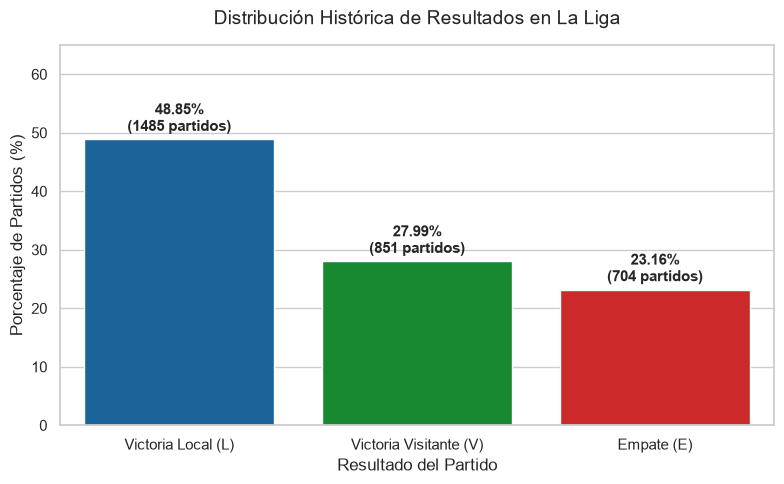

In [18]:
# Vizualicacion de local visitante y empate
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))


conteos_pct = df_match['resultado'].value_counts(normalize=True) * 100
conteos_abs = df_match['resultado'].value_counts()
orden_clases = ['L', 'V', 'E'] # Local, Visitante, Empate
ax = sns.barplot(
    x=conteos_pct.loc[orden_clases].index, 
    y=conteos_pct.loc[orden_clases].values, 
    palette=["#0667ac", "#059c26", "#e70f0f"] 
)
for i, p in enumerate(ax.patches):
    porcentaje = p.get_height()
    cantidad = conteos_abs.loc[orden_clases[i]] # Extraemos los partidos ganados y empatados
    
    
    texto_etiqueta = f'{porcentaje:.2f}%\n({cantidad} partidos)'
    
    ax.annotate(texto_etiqueta, 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 15), 
                textcoords='offset points',
                fontsize=11, fontweight='bold')

plt.title('Distribución Histórica de Resultados en La Liga', fontsize=14, pad=15)
plt.xlabel('Resultado del Partido', fontsize=12)
plt.ylabel('Porcentaje de Partidos (%)', fontsize=12)
plt.ylim(0, 65) 
plt.xticks(ticks=[0, 1, 2], labels=['Victoria Local (L)', 'Victoria Visitante (V)', 'Empate (E)'])
plt.tight_layout()
plt.show()

Nota del EDA: Tratamiento de Titulares Faltantes

Identifique que en 333 partidos tienen al menos un jugador titular sin identificar en la base de datos. 

Los IDs faltantes se estandarizaron estrictamente como nulos reales (`NaN`). Dado que los IDs numéricos de los jugadores no entrarán directamente al modelo de Machine Learning para evitar ruido, en caso de tratar con los jugadores recomiendo calcular la **calidad promedio del equipo usando únicamente a los titulares disponibles**. 

Así evitamos inventar información y permitimos que Pandas calcule el promedio de nivel del equipo sin que el código falle.

In [16]:
# Listar las 22 columnas correspondientes a los titulares de ambos equipos
columnas_jugadores = [f'home_player_{i}' for i in range(1, 12)] + [f'away_player_{i}' for i in range(1, 12)]

# Crear una máscara booleana que busca filas con al menos un NaN en esas columnas
partidos_incompletos = df_match[columnas_jugadores].isna().any(axis=1)

# Contar el total de nulos
total_incompletos = partidos_incompletos.sum()
print(f"Partidos con al menos un titular sin identificar: {total_incompletos}")

# Aislar el DataFrame para visualizar exactamente dónde están los nulos
df_sin_titulares = df_match[partidos_incompletos]
display(df_sin_titulares[['date', 'home_team_api_id', 'away_team_api_id'] + columnas_jugadores].head(10))

Partidos con al menos un titular sin identificar: 333


,date,home_team_api_id,away_team_api_id,home_player_1,home_player_2,home_player_3,home_player_4,home_player_5,home_player_6,home_player_7,home_player_8,home_player_9,home_player_10,home_player_11,away_player_1,away_player_2,away_player_3,away_player_4,away_player_5,away_player_6,away_player_7,away_player_8,away_player_9,away_player_10,away_player_11
3,2008-08-31,8388,8634,75195.0,75199.0,NaN,38561.0,74435.0,102374.0,38008.0,74721.0,38550.0,NaN,38526.0,32657.0,33988.0,30661.0,30740.0,30738.0,39854.0,36615.0,30955.0,30981.0,33639.0,30626.0
5,2008-08-31,9869,8305,38520.0,74743.0,75395.0,74739.0,74752.0,33887.0,78404.0,NaN,74770.0,24383.0,41294.0,34382.0,37470.0,32675.0,37427.0,37468.0,52490.0,37471.0,30468.0,37461.0,37469.0,37474.0
7,2008-08-30,8558,10281,25563.0,28439.0,33768.0,NaN,75196.0,18592.0,24099.0,32766.0,33872.0,32764.0,24852.0,96623.0,37597.0,33022.0,38065.0,2790.0,33820.0,33586.0,18395.0,38431.0,33729.0,39142.0
8,2008-08-31,8315,9865,33764.0,33025.0,33027.0,33993.0,NaN,96619.0,33024.0,37410.0,30277.0,33030.0,NaN,96613.0,74403.0,74663.0,18501.0,37622.0,37419.0,75239.0,5243.0,38581.0,46384.0,75310.0
9,2008-08-31,9906,9864,39989.0,37413.0,30839.0,30689.0,34103.0,33632.0,38492.0,25924.0,30663.0,37412.0,38460.0,33826.0,33843.0,5233.0,41707.0,38025.0,33666.0,38151.0,NaN,37450.0,38479.0,43310.0
10,2008-11-09,8302,8479,33986.0,70255.0,33812.0,33990.0,33848.0,33991.0,31014.0,34000.0,33992.0,30443.0,33989.0,33958.0,42310.0,37440.0,NaN,37423.0,75398.0,37448.0,74747.0,38035.0,NaN,18628.0
12,2008-11-09,8388,8603,75195.0,75199.0,102614.0,38561.0,74435.0,38008.0,NaN,75216.0,46211.0,38550.0,102002.0,46531.0,31303.0,30750.0,33655.0,37426.0,33665.0,42173.0,37422.0,25571.0,38889.0,18164.0
13,2008-11-09,9783,8558,33018.0,33756.0,37451.0,34104.0,41167.0,30271.0,37449.0,38573.0,37441.0,31045.0,37446.0,25563.0,28439.0,NaN,38385.0,75196.0,18592.0,24099.0,33773.0,24852.0,37429.0,32764.0
19,2008-11-09,8661,8315,32678.0,24131.0,33849.0,33856.0,33861.0,37491.0,31498.0,37631.0,38398.0,37411.0,33028.0,33764.0,33025.0,33993.0,33027.0,154938.0,30287.0,37410.0,33866.0,NaN,37408.0,33030.0
22,2008-11-16,8558,8388,25563.0,24137.0,33768.0,28439.0,75196.0,18592.0,24099.0,33773.0,24852.0,37429.0,32764.0,75195.0,75199.0,102614.0,38561.0,74435.0,38008.0,NaN,75216.0,38550.0,97226.0,102002.0


In [ ]:
print("\n2. TABLA: CATÁLOGO DE EQUIPOS (Team)")
display(df_team.head())

print("\n3. TABLA: ATRIBUTOS DE EQUIPOS (Team Attributes)")
display(df_team_attr.head())

print("\n4. TABLA: CATÁLOGO DE JUGADORES (Player)")
display(df_player.head())

print("\n5. TABLA: ESTADÍSTICAS DE JUGADORES (Player Attributes)")
display(df_player_attr.head())


2. TABLA: CATÁLOGO DE EQUIPOS (Team)


,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
0,43035,10267,461.0,Valencia CF,VAL
1,43036,8661,453.0,RCD Mallorca,MAL
2,43037,8371,479.0,CA Osasuna,OSA
3,43038,10205,483.0,Villarreal CF,VIL
4,43039,9783,242.0,RC Deportivo de La Coruña,COR



3. TABLA: ATRIBUTOS DE EQUIPOS (Team Attributes)


,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlaySpeedClass,buildUpPlayDribbling,buildUpPlayDribblingClass,buildUpPlayPassing,buildUpPlayPassingClass,buildUpPlayPositioningClass,chanceCreationPassing,chanceCreationPassingClass,chanceCreationCrossing,chanceCreationCrossingClass,chanceCreationShooting,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressure,defencePressureClass,defenceAggression,defenceAggressionClass,defenceTeamWidth,defenceTeamWidthClass,defenceDefenderLineClass
0,40,1861,9865,2010-02-22 00:00:00,65,Balanced,NaN,Little,45,Mixed,Organised,45,Normal,45,Normal,70,Lots,Organised,70,High,65,Press,30,Narrow,Cover
1,41,1861,9865,2011-02-22 00:00:00,55,Balanced,NaN,Little,53,Mixed,Organised,57,Normal,54,Normal,69,Lots,Organised,58,Medium,68,Double,67,Wide,Cover
2,42,1861,9865,2012-02-22 00:00:00,42,Balanced,NaN,Little,70,Long,Organised,57,Normal,54,Normal,40,Normal,Organised,37,Medium,53,Press,45,Normal,Cover
3,43,1861,9865,2013-09-20 00:00:00,46,Balanced,NaN,Little,65,Mixed,Organised,57,Normal,54,Normal,40,Normal,Organised,37,Medium,53,Press,45,Normal,Cover
4,44,1861,9865,2014-09-19 00:00:00,46,Balanced,41.0,Normal,65,Mixed,Organised,57,Normal,54,Normal,40,Normal,Organised,37,Medium,53,Press,45,Normal,Cover



4. TABLA: CATÁLOGO DE JUGADORES (Player)


,id,player_api_id,player_name,player_fifa_api_id,birthday,height,weight
0,14,40719,Aaron Niguez,183853,1989-04-26 00:00:00,170.18,143
1,21,167027,Abdelaziz Barrada,192274,1989-06-19 00:00:00,177.80,161
2,24,42664,Abdelkader Ghezzal,178063,1984-12-05 00:00:00,182.88,172
3,36,67334,Abdoul Karim Yoda,188232,1988-10-25 00:00:00,182.88,161
4,38,39562,Abdoulay Konko,161999,1984-03-09 00:00:00,182.88,157



5. TABLA: ESTADÍSTICAS DE JUGADORES (Player Attributes)


,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,attacking_work_rate,defensive_work_rate,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,free_kick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
0,243,183853,40719,2016-04-28 00:00:00,70.0,71.0,left,medium,medium,64.0,67.0,54.0,64.0,61.0,75.0,66.0,68.0,56.0,76.0,82.0,78.0,82.0,66.0,84.0,74.0,70.0,67.0,51.0,72.0,45.0,45.0,70.0,62.0,67.0,36.0,31.0,37.0,14.0,13.0,9.0,15.0,10.0
1,244,183853,40719,2016-04-14 00:00:00,70.0,72.0,left,medium,medium,64.0,67.0,54.0,64.0,61.0,75.0,66.0,68.0,56.0,76.0,82.0,78.0,82.0,66.0,84.0,74.0,70.0,67.0,51.0,72.0,45.0,45.0,70.0,62.0,67.0,36.0,31.0,37.0,14.0,13.0,9.0,15.0,10.0
2,245,183853,40719,2016-01-21 00:00:00,70.0,72.0,left,medium,medium,64.0,67.0,54.0,64.0,61.0,75.0,66.0,68.0,56.0,76.0,82.0,78.0,82.0,66.0,84.0,74.0,70.0,67.0,51.0,72.0,45.0,45.0,70.0,62.0,67.0,36.0,31.0,37.0,14.0,13.0,9.0,15.0,10.0
3,246,183853,40719,2015-12-17 00:00:00,71.0,73.0,left,medium,medium,64.0,67.0,54.0,64.0,61.0,76.0,66.0,68.0,60.0,77.0,82.0,78.0,82.0,66.0,84.0,74.0,70.0,73.0,51.0,72.0,45.0,45.0,70.0,62.0,67.0,36.0,31.0,37.0,14.0,13.0,9.0,15.0,10.0
4,247,183853,40719,2015-11-12 00:00:00,71.0,73.0,left,medium,medium,64.0,67.0,54.0,64.0,61.0,76.0,66.0,68.0,60.0,77.0,82.0,78.0,82.0,66.0,84.0,68.0,70.0,73.0,51.0,62.0,45.0,45.0,70.0,62.0,67.0,36.0,31.0,37.0,14.0,13.0,9.0,15.0,10.0
